## EXPÉRIENCE A : comparaison des architectures ANN (ANN-1 à ANN-5)
#### Objectif :  evaluer si la profondeur ou la largeur du réseau classe mieux l'occupation du sol 

#### Principe directeur : une seule chose change d'un modèle à l'autre, l'architecture.


In [1]:
# importation des données propres

import os
import time
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 
import keras
from keras import layers
 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             cohen_kappa_score, matthews_corrcoef)

Initialisation des parametres et definition des fonctions utiles pour cette experience ainsi que les autres

In [4]:
data= pd.read_csv("donnees_propres.csv", sep=",")
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  1000 non-null   int64  
 1   Classes1            1000 non-null   int64  
 2   class_name          1000 non-null   object 
 3   Classes1_origine    1000 non-null   int64  
 4   class_name_origine  1000 non-null   object 
 5   B1                  1000 non-null   float64
 6   B2                  1000 non-null   float64
 7   B3                  1000 non-null   float64
 8   B4                  1000 non-null   float64
 9   B5                  1000 non-null   float64
 10  B6                  1000 non-null   float64
 11  B7                  1000 non-null   float64
 12  B8                  1000 non-null   float64
 13  B9                  1000 non-null   float64
 14  B10                 1000 non-null   float64
 15  NDVI                1000 non-null   float64
 16  EVI    

In [6]:
SEED_PARTITION = 42          # graine du découpage train / validation / test (fixe)
GRAINES = [0, 1, 2, 3, 4]    # 5 initialisations des poids par architecture 
                             
TAUX_APPRENTISSAGE = 1e-3    # taux d'apprentissage d'Adam 
TAILLE_LOT = 32              
EPOCHS_MAX = 200             
PATIENCE = 20                # arrêt si la perte de validation ne s'améliore plus pendant 20 epochs
TAUX_DROPOUT = 0.2  

DOSSIER_SORTIE = "resultats/experience_A"
 

In [7]:
 
# Variables d'entrée : 10 bandes + 9 indices ; Les coordonnées seront introduites dans l'experience F
BANDES = [f"B{i}" for i in range(1, 11)]
INDICES = ["NDVI", "EVI", "NDRE", "SAVI", "NDMI", "NDWI", "MSI", "BSI", "BI"]
VARIABLES = BANDES + INDICES
 

X = data[VARIABLES].to_numpy(dtype="float32")
encodeur = LabelEncoder()                       # transforme les noms de classes en entiers 0..7
y = encodeur.fit_transform(data["class_name"])
NOMS_CLASSES = list(encodeur.classes_)
N_CLASSES = len(NOMS_CLASSES)
 
print(f"{X.shape[0]} observations, {X.shape[1]} variables, {N_CLASSES} classes")
print(pd.Series(data["class_name"]).value_counts().to_string())
 
# Découpage train / validation / test (70 / 15 / 15) , stratifié

idx = np.arange(len(y))
idx_train, idx_temp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED_PARTITION)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=y[idx_temp],
                                     random_state=SEED_PARTITION)
 
# On sauvegarde les partitions pour pouvoir réutiliser EXACTEMENT les mêmes par la suite
partitions = pd.DataFrame({"id": data["id"], "ensemble": ""})
partitions.loc[idx_train, "ensemble"] = "train"
partitions.loc[idx_val, "ensemble"] = "validation"
partitions.loc[idx_test, "ensemble"] = "test"           # reservé a l'evaluation finale du modele 
partitions.to_csv(os.path.join(DOSSIER_SORTIE, "partitions.csv"), index=False)
 
print("\nEffectifs par classe et par ensemble :")
print(pd.crosstab(data["class_name"], partitions["ensemble"]).to_string())

#  Standardisation sur l'entraînement pour eviter la fuite de données
normaliseur = StandardScaler().fit(X[idx_train])         # le normaliseur apprend les parametres sur le train puis l'applique afin d'eviter une fuite de donnée
X_train, y_train = normaliseur.transform(X[idx_train]), y[idx_train]
X_val, y_val = normaliseur.transform(X[idx_val]), y[idx_val]
 
# Définition des 5 architectures
# Toutes : entrée = 19 variables, couches cachées ReLU, sortie softmax à 8 neurones .
ARCHITECTURES = {
    "ANN-1": [32],
    "ANN-2": [64, 32],
    "ANN-3": [128, 64, 32],
    "ANN-4": [128, 128, 64, 32],
    "ANN-5": [128, 64, 32],      # = ANN-3 + Batch Normalization + Dropout 
}
 
 
def construire_modele(nom, couches):
    """Construit un réseau dense (MLP) à partir de la liste des neurones par couche cachée."""
    modele = keras.Sequential(name=nom.replace("-", "_"))
    modele.add(keras.Input(shape=(len(VARIABLES),)))
    for n in couches:
        if nom == "ANN-5":
            # Ordre : Dense -> BatchNorm -> activation
            modele.add(layers.Dense(n))
            modele.add(layers.BatchNormalization())
            modele.add(layers.Activation("relu"))
        else:
            modele.add(layers.Dense(n, activation="relu"))
    if nom == "ANN-5":
        # Dropout placé APRÈS la dernière BatchNorm 
        modele.add(layers.Dropout(TAUX_DROPOUT))
    modele.add(layers.Dense(N_CLASSES, activation="softmax"))
 
    # Perte : entropie croisée multiclasse ; « sparse » car y contient des entiers (0..7)
    modele.compile(optimizer=keras.optimizers.Adam(learning_rate=TAUX_APPRENTISSAGE) ,    # on utilise l'optimiseur adam,
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
    return modele
 
def nb_parametres_entrainables(modele):
    return int(sum(np.prod(w.shape) for w in modele.trainable_weights))
 
 
# Vérification : nombre de paramètres de chaque architecture
for nom, couches in ARCHITECTURES.items():
    m = construire_modele(nom, couches)
    print(f"{nom} : {' -> '.join(map(str, [len(VARIABLES)] + couches + [N_CLASSES]))} "
          f"| {nb_parametres_entrainables(m):,} paramètres entraînables".replace(",", " "))
 
 


1000 observations, 19 variables, 8 classes
class_name
Rubber and Other Crops                  601
Savannas                                102
Coffee and Cocoa                        101
Forest                                   78
Human Infrastructure and Settlements     59
Wetlands                                 27
Water Bodies                             24
Bare Soil and Rock Outcrops               8

Effectifs par classe et par ensemble :
ensemble                              test  train  validation
class_name                                                   
Bare Soil and Rock Outcrops              2      5           1
Coffee and Cocoa                        15     71          15
Forest                                  11     55          12
Human Infrastructure and Settlements     9     41           9
Rubber and Other Crops                  90    421          90
Savannas                                16     71          15
Water Bodies                             3     17         

Les données ont été réparties en trois sous-ensembles : 70 % pour l'entraînement, 15 % pour la validation et 15 % pour le test. La méthode de stratification (stratify) a été utilisée afin de conserver, autant que possible, les proportions des différentes classes dans chaque sous-ensemble. Toutefois, le jeu de données présente un déséquilibre important entre les classes.
Les cinq architectures utilisent 19 variables d'entrée et huit neurones de sortie, correspondant aux huit classes à prédire. L'ANN-1 constitue l'architecture la plus simple, avec une seule couche cachée de 32 neurones et 904 paramètres entraînables. L'ANN-2 comporte deux couches cachées de 64 et 32 neurones, pour un total de 3 624 paramètres. L'ANN-3 est constitué de trois couches cachées de 128, 64 et 32 neurones, avec 13 160 paramètres entraînables. L'ANN-4 approfondit cette architecture en ajoutant une couche cachée supplémentaire de 128 neurones, portant le nombre de paramètres à 29 672.

L'augmentation du nombre de couches et de paramètres permet aux réseaux de disposer d'une capacité plus importante pour apprendre les relations non linéaires entre les variables spectrales et les classes d'occupation du sol. Cependant, une architecture plus complexe n'est pas nécessairement plus performante, notamment lorsque le nombre d'observations disponibles est limité. Elle peut également présenter un risque accru de surapprentissage, lorsque le modèle apprend trop précisément les caractéristiques des données d'entraînement et généralise moins bien à de nouvelles observations.

L'ANN-5 reprend l'architecture de l'ANN-3, à laquelle sont ajoutées deux techniques de régularisation : la normalisation par lots (Batch Normalization) et le Dropout. La normalisation par lots contribue à stabiliser les activations au cours de l'apprentissage, tandis que le Dropout désactive temporairement une partie des neurones pendant l'entraînement afin de limiter la dépendance excessive du réseau à certaines connexions. Ces mécanismes visent à améliorer la généralisation du modèle et à réduire le risque de surapprentissage


In [23]:
#le kappa est contesté pour l'évaluation des cartes  d'ou le retrait dans nos metriques(Foody, 2020)

def calculer_metriques(y_vrai, y_pred):
    return {   
        "accuracy": accuracy_score(y_vrai, y_pred),
        "precision_macro": precision_score(y_vrai, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_vrai, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_vrai, y_pred, average="macro", zero_division=0),
        "f1_pondere": f1_score(y_vrai, y_pred, average="weighted", zero_division=0),
        "mcc": matthews_corrcoef(y_vrai, y_pred),
    }

#  Entraînement : 5 architectures x 5 graines, mêmes données, mêmes conditions
resultats = []        # une ligne par (architecture, graine)
historiques = {}      # courbes d'apprentissage, pour les graphiques
f1_par_classe = {}    # F1 de chaque classe sur la validation
 
for nom, couches in ARCHITECTURES.items():
    for graine in GRAINES:
        keras.utils.set_random_seed(graine)          # même initialisation reproductible pour chaque graine
        modele = construire_modele(nom, couches)
 
        # Arrêt anticipé : on surveille la perte de validation et on garde les meilleurs poids
        arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                              restore_best_weights=True)
        debut = time.perf_counter()
        hist = modele.fit(X_train, y_train, validation_data=(X_val, y_val),
                          epochs=EPOCHS_MAX, batch_size=TAILLE_LOT,
                          callbacks=[arret], verbose =0)   # on sature pas le terminal avec l'historique
        duree = time.perf_counter() - debut
 
        # Prédiction = classe de plus forte probabilité softmax
        pred_train = modele.predict(X_train, verbose=0).argmax(axis=1)
        pred_val = modele.predict(X_val, verbose=0).argmax(axis=1)
        m_train = calculer_metriques(y_train, pred_train)
        m_val = calculer_metriques(y_val, pred_val)
 
        resultats.append({
            "modele": nom, "graine": graine,
            "parametres": nb_parametres_entrainables(modele),
            "epochs_effectuees": len(hist.history["loss"]),
            "meilleure_epoch": int(np.argmin(hist.history["val_loss"])) + 1,
            "temps_s": duree,
            "perte_val": float(np.min(hist.history["val_loss"])),
            **{f"val_{k}": v for k, v in m_val.items()},
            "train_f1_macro": m_train["f1_macro"],
            # Écart entraînement - validation : indicateur de surapprentissage
            "ecart_f1_train_val": m_train["f1_macro"] - m_val["f1_macro"],
        })
        historiques[(nom, graine)] = hist.history
        f1_par_classe[(nom, graine)] = f1_score(y_val, pred_val, average=None,
                                                labels=range(N_CLASSES), zero_division=0)
        print(f"{nom} | graine {graine} | {len(hist.history['loss'])} epochs | "
              f"Macro-F1 val = {m_val['f1_macro']:.3f} | {duree:.1f} s")
 
resultats = pd.DataFrame(resultats)
resultats.to_csv(os.path.join(DOSSIER_SORTIE, "resultats_detailles.csv"), index=False)
 
# 7. Tableau récapitulatif : moyenne ± écart-type sur les 5 graines (sur la VALIDATION)
colonnes = ["val_f1_macro", "val_accuracy", "val_precision_macro", "val_recall_macro",
            "val_f1_pondere", "val_mcc", "ecart_f1_train_val",
            "meilleure_epoch", "temps_s"]
recap = resultats.groupby("modele")[colonnes].agg(["mean", "std"])
recap.insert(0, ("parametres", ""), resultats.groupby("modele")["parametres"].first())
 
# Version lisible : « moyenne ± écart-type »
tableau = pd.DataFrame(index=recap.index)
tableau["Paramètres"] = recap[("parametres", "")]
for c in colonnes:
    dec = 0 if c in ("meilleure_epoch",) else (1 if c == "temps_s" else 3)
    tableau[c] = [f"{m:.{dec}f} ± {s:.{dec}f}" for m, s in zip(recap[(c, "mean")], recap[(c, "std")])]
tableau.to_csv(os.path.join(DOSSIER_SORTIE, "recapitulatif_architectures.csv"))

display(tableau)                



ANN-1 | graine 0 | 76 epochs | Macro-F1 val = 0.340 | 84.4 s
ANN-1 | graine 1 | 85 epochs | Macro-F1 val = 0.328 | 63.9 s
ANN-1 | graine 2 | 75 epochs | Macro-F1 val = 0.342 | 45.6 s
ANN-1 | graine 3 | 133 epochs | Macro-F1 val = 0.349 | 42.5 s
ANN-1 | graine 4 | 131 epochs | Macro-F1 val = 0.300 | 58.2 s
ANN-2 | graine 0 | 67 epochs | Macro-F1 val = 0.348 | 22.0 s
ANN-2 | graine 1 | 57 epochs | Macro-F1 val = 0.343 | 19.3 s
ANN-2 | graine 2 | 48 epochs | Macro-F1 val = 0.320 | 15.6 s
ANN-2 | graine 3 | 60 epochs | Macro-F1 val = 0.332 | 18.3 s
ANN-2 | graine 4 | 65 epochs | Macro-F1 val = 0.347 | 20.6 s
ANN-3 | graine 0 | 54 epochs | Macro-F1 val = 0.385 | 18.4 s
ANN-3 | graine 1 | 38 epochs | Macro-F1 val = 0.351 | 13.1 s
ANN-3 | graine 2 | 38 epochs | Macro-F1 val = 0.348 | 15.1 s
ANN-3 | graine 3 | 46 epochs | Macro-F1 val = 0.377 | 16.9 s
ANN-3 | graine 4 | 31 epochs | Macro-F1 val = 0.324 | 11.5 s
ANN-4 | graine 0 | 34 epochs | Macro-F1 val = 0.347 | 12.8 s
ANN-4 | graine 1 | 37 

,Paramètres,val_f1_macro,val_accuracy,val_precision_macro,val_recall_macro,val_f1_pondere,val_mcc,ecart_f1_train_val,meilleure_epoch,temps_s
modele,,,,,,,,,,
ANN-1,904,0.332 ± 0.019,0.641 ± 0.013,0.423 ± 0.068,0.337 ± 0.015,0.568 ± 0.015,0.306 ± 0.031,0.101 ± 0.041,80 ± 29,58.9 ± 16.8
ANN-2,3624,0.338 ± 0.012,0.639 ± 0.010,0.381 ± 0.021,0.345 ± 0.011,0.570 ± 0.009,0.309 ± 0.017,0.116 ± 0.017,39 ± 8,19.2 ± 2.4
ANN-3,13160,0.357 ± 0.024,0.641 ± 0.009,0.396 ± 0.019,0.366 ± 0.027,0.584 ± 0.020,0.330 ± 0.035,0.100 ± 0.007,21 ± 9,15.0 ± 2.8
ANN-4,29672,0.352 ± 0.016,0.641 ± 0.007,0.375 ± 0.035,0.365 ± 0.019,0.583 ± 0.014,0.334 ± 0.025,0.095 ± 0.022,16 ± 4,13.8 ± 1.2
ANN-5,13608,0.332 ± 0.023,0.643 ± 0.009,0.456 ± 0.025,0.328 ± 0.018,0.560 ± 0.023,0.294 ± 0.033,0.122 ± 0.035,19 ± 3,19.1 ± 1.9


Les performances des cinq architectures de réseaux de neurones artificiels ont été évaluées sur l'ensemble de validation en réalisant cinq expériences avec des graines aléatoires différentes.

L'analyse du Macro-F1 montre que l'ANN-3 obtient le meilleur score moyen, avec 0,357 ± 0,024, suivi de l'ANN-4, avec 0,352 ± 0,016. L'ANN-2 atteint 0,338 ± 0,012, tandis que l'ANN-1 et l'ANN-5 obtiennent chacun un score moyen de 0,332, avec des écarts-types respectifs de 0,019 et 0,023. Ces résultats suggèrent que l'augmentation de la capacité du réseau, entre les architectures ANN-1 et ANN-3, améliore la qualité moyenne de classification des différentes classes. Toutefois, l'ajout d'une couche cachée supplémentaire dans l'ANN-4 n'apporte pas d'amélioration notable du Macro-F1 par rapport à l'ANN-3.



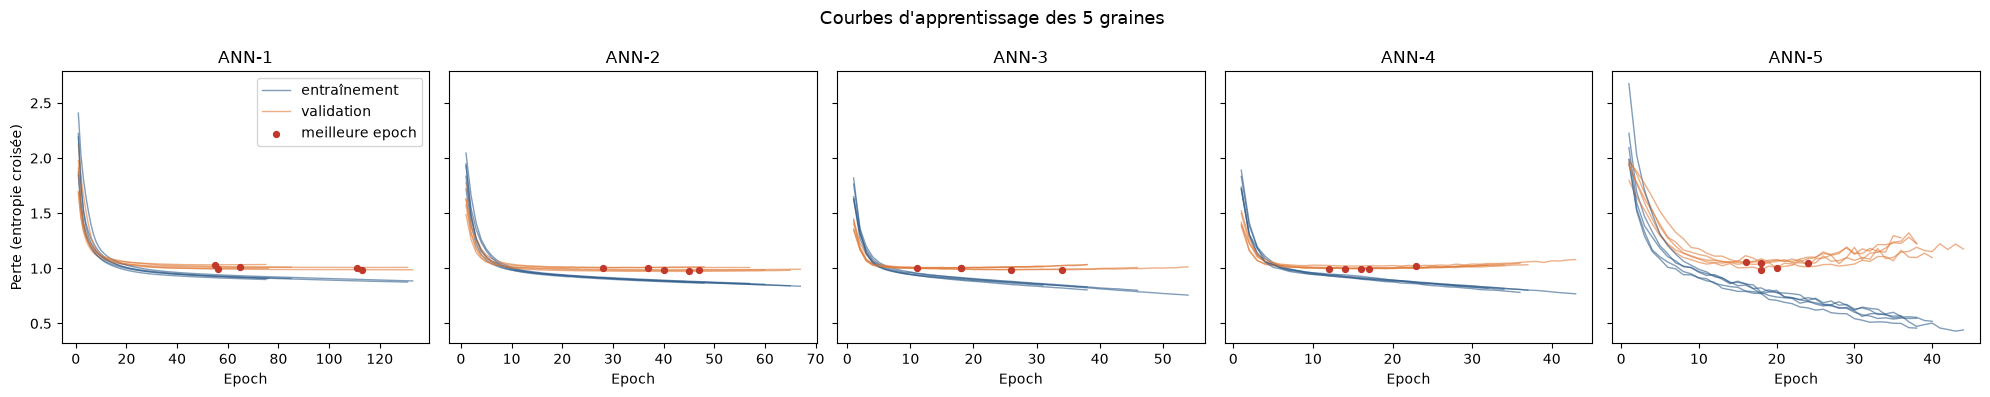

In [16]:
#  8. Graphique 1 : courbes d'apprentissage des 5 graines
# Chaque trait = un entraînement complet (pas de moyenne : les durées diffèrent à cause de
# l'arrêt anticipé). 

fig, axes = plt.subplots(1, len(ARCHITECTURES), figsize=(20, 4), sharey=True)
for ax, nom in zip(axes, ARCHITECTURES):
    for graine in GRAINES:
        h = historiques[(nom, graine)]
        epochs = np.arange(1, len(h["loss"]) + 1)
        premiere = graine == GRAINES[0]          # pour n'afficher la légende qu'une fois
        ax.plot(epochs, h["loss"], color="#2e5c8b", lw=1, alpha=0.6,
                label="entraînement" if premiere else None)
        ax.plot(epochs, h["val_loss"], color="#e07b39", lw=1, alpha=0.6,
                label="validation" if premiere else None)
        meilleure = int(np.argmin(h["val_loss"]))
        ax.scatter(meilleure + 1, h["val_loss"][meilleure], color="#c0392b", s=18, zorder=3,
                   label="meilleure epoch" if premiere else None)
    ax.set_title(nom)
    ax.set_xlabel("Epoch")
axes[0].set_ylabel("Perte (entropie croisée)")
axes[0].legend()
fig.suptitle("Courbes d'apprentissage des 5 graines ", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_SORTIE, "courbes_apprentissage.png"), dpi=150)
plt.show()



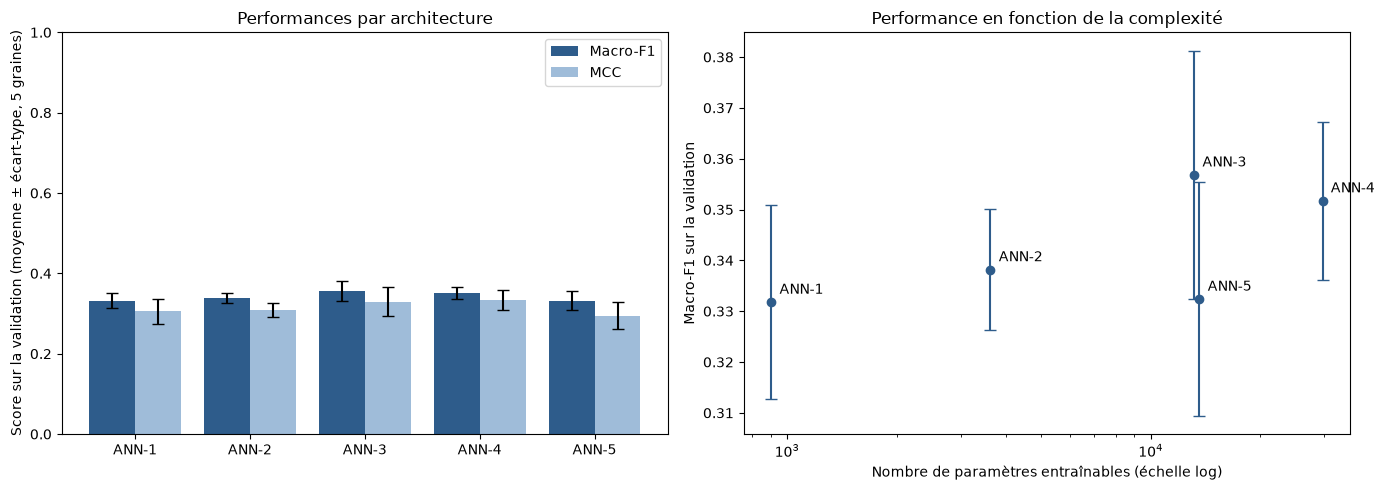

In [ ]:
# 9. Graphique 2 : comparaison des performances et lien avec la complexité
# Macro-F1 (critère principal) et MCC (score global robuste au déséquilibre).
#le kappa est contesté pour l'évaluation des cartes (Foody, 2020)

moy = resultats.groupby("modele").agg(f1=("val_f1_macro", "mean"), f1_sd=("val_f1_macro", "std"),
                                      mcc=("val_mcc", "mean"), mcc_sd=("val_mcc", "std"),
                                      parametres=("parametres", "first")).loc[list(ARCHITECTURES)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(moy))
axes[0].bar(x - 0.2, moy["f1"], 0.4, yerr=moy["f1_sd"], capsize=4, label="Macro-F1", color="#2e5c8b")
axes[0].bar(x + 0.2, moy["mcc"], 0.4, yerr=moy["mcc_sd"], capsize=4, label="MCC", color="#9fbcd9")
axes[0].set_xticks(x, moy.index)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Score sur la validation (moyenne ± écart-type, 5 graines)")
axes[0].set_title("Performances par architecture")
axes[0].legend(loc="upper right")

axes[1].errorbar(moy["parametres"], moy["f1"], yerr=moy["f1_sd"], fmt="o", capsize=4, color="#2e5c8b")
for nom, ligne in moy.iterrows():
    axes[1].annotate(nom, (ligne["parametres"], ligne["f1"]), xytext=(6, 6), textcoords="offset points")
axes[1].set_xscale("log")
axes[1].set_xlabel("Nombre de paramètres entraînables (échelle log)")
axes[1].set_ylabel("Macro-F1 sur la validation")
axes[1].set_title("Performance en fonction de la complexité")
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_SORTIE, "comparaison_architectures.png"), dpi=150)
plt.show()

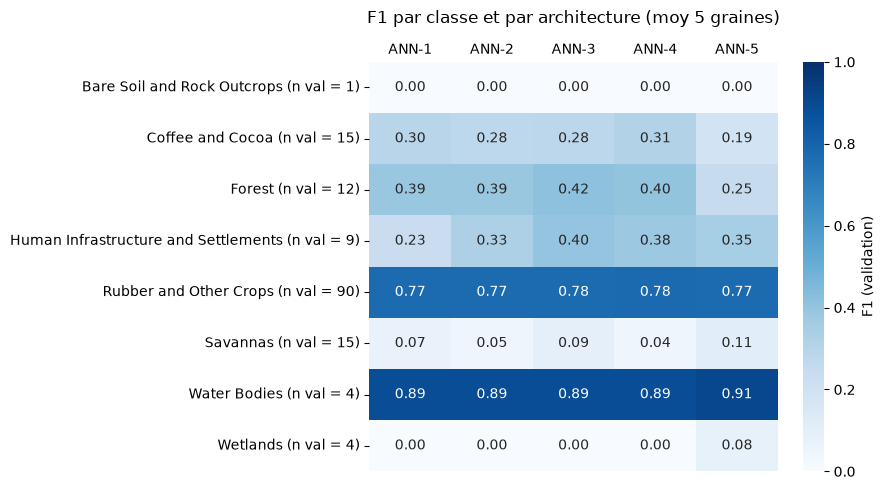

In [20]:
# 10. Graphique 3 : F1 par classe (validation, moyenne des 5 graines)
# Permet de voir si la profondeur aide surtout les classes minoritaires ou les classes proches.

f1_classes = pd.DataFrame({nom: np.mean([f1_par_classe[(nom, g)] for g in GRAINES], axis=0)
                           for nom in ARCHITECTURES}, index=NOMS_CLASSES)
effectifs_val = pd.Series(y_val).value_counts().reindex(range(N_CLASSES), fill_value=0).to_numpy()
f1_classes.index = [f"{c} (n val = {n})" for c, n in zip(NOMS_CLASSES, effectifs_val)]
f1_classes.to_csv(os.path.join(DOSSIER_SORTIE, "f1_par_classe.csv"))

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(f1_classes, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "F1 (validation)"})
ax.xaxis.tick_top()                     # noms des architectures au-dessus du graphique
ax.tick_params(axis="x", length=0)
ax.set_title("F1 par classe et par architecture (moy 5 graines)", pad=28)
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_SORTIE, "f1_par_classe.png"), dpi=150)
plt.show()
# certaines classes n'ont que 1 à 4 observations en validation
# leur F1 est très instable.